In [1]:
!pip -q install ucimlrepo shap scikit-learn pandas numpy matplotlib seaborn joblib

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib
import requests

from io import BytesIO
from ucimlrepo import fetch_ucirepo
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

print("SHAP version:", shap.__version__)
print("Libraries imported successfully!")

SHAP version: 0.54.1
Libraries imported successfully!


In [3]:
# Load original dataset
dataset = fetch_ucirepo(id=601)

X = dataset.data.features[[
    "Type",
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]]

y = dataset.data.targets["Machine failure"]

# Download trained model from GitHub
model_url = (
    "https://raw.githubusercontent.com/"
    "posinasettymanjusha/Machineguard-ML/"
    "main/models/machineguard_model.joblib"
)

response = requests.get(model_url)
response.raise_for_status()

model_artifact = joblib.load(BytesIO(response.content))

final_model = model_artifact["model"]
final_threshold = model_artifact["threshold"]

print("Dataset shape:", X.shape)
print("Model loaded successfully!")
print("Selected threshold:", final_threshold)

Dataset shape: (10000, 6)
Model loaded successfully!
Selected threshold: 0.26666666666666666


In [4]:
# Extract preprocessing and Random Forest components
preprocessor = final_model.named_steps["preprocessor"]
rf_model = final_model.named_steps["model"]

# Select 300 records for SHAP analysis
X_sample = X.sample(n=300, random_state=42)

# Apply the same preprocessing used during training
X_transformed = preprocessor.transform(X_sample)

# Get transformed feature names
feature_names = preprocessor.get_feature_names_out()

# Convert to DataFrame for easier interpretation
X_shap = pd.DataFrame(
    X_transformed,
    columns=feature_names
)

print("Original sample shape:", X_sample.shape)
print("Transformed sample shape:", X_shap.shape)
print("\nFeatures used by SHAP:")
print(list(feature_names))

Original sample shape: (300, 6)
Transformed sample shape: (300, 8)

Features used by SHAP:
['num__Air temperature', 'num__Process temperature', 'num__Rotational speed', 'num__Torque', 'num__Tool wear', 'cat__Type_H', 'cat__Type_L', 'cat__Type_M']


In [5]:
# Create SHAP Tree Explainer
explainer = shap.TreeExplainer(rf_model)

# Calculate SHAP values
shap_explanation = explainer(X_shap)

# Extract values for the failure class (class 1)
shap_values = shap_explanation.values

if shap_values.ndim == 3:
    shap_values = shap_values[:, :, 1]

print("SHAP calculation completed!")
print("SHAP values shape:", shap_values.shape)

SHAP calculation completed!
SHAP values shape: (300, 8)


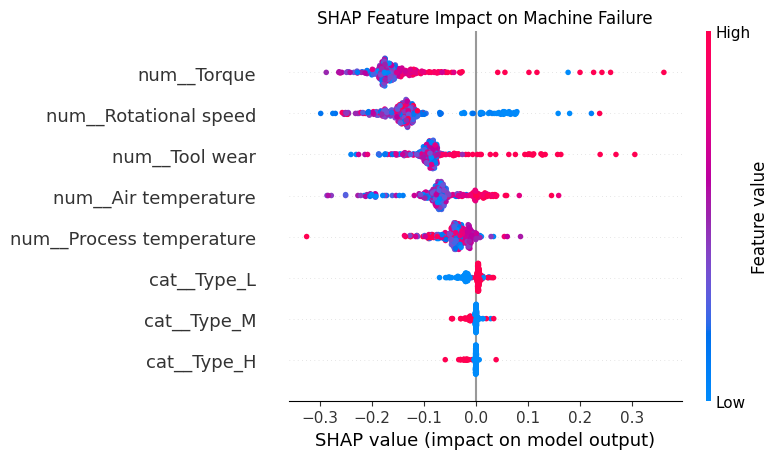

In [6]:
plt.figure(figsize=(10, 6))

shap.summary_plot(
    shap_values,
    X_shap,
    show=False
)

plt.title("SHAP Feature Impact on Machine Failure")
plt.tight_layout()
plt.show()

In [7]:
# Calculate mean absolute SHAP values
mean_shap = np.abs(shap_values).mean(axis=0)

# Create feature importance dataframe
shap_importance = pd.DataFrame({
    "Feature": feature_names,
    "Mean Absolute SHAP": mean_shap
})

# Sort from highest to lowest
shap_importance = shap_importance.sort_values(
    by="Mean Absolute SHAP",
    ascending=False
)

display(shap_importance.round(4))

,Feature,Mean Absolute SHAP
3,num__Torque,0.1616
2,num__Rotational speed,0.1375
4,num__Tool wear,0.0952
0,num__Air temperature,0.0733
1,num__Process temperature,0.0406
6,cat__Type_L,0.0120
7,cat__Type_M,0.0049
5,cat__Type_H,0.0026


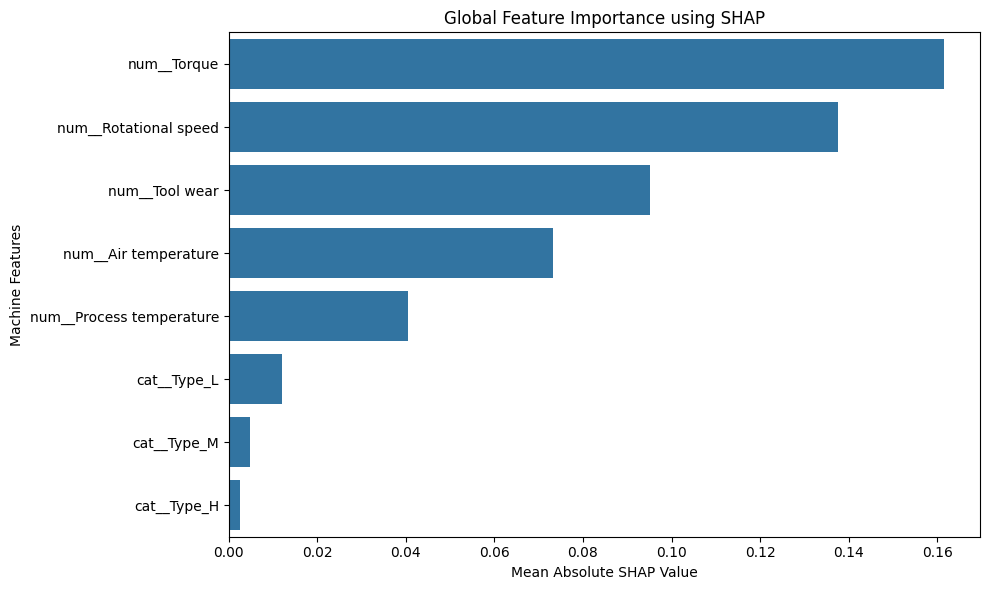

In [8]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=shap_importance,
    x="Mean Absolute SHAP",
    y="Feature"
)

plt.title("Global Feature Importance using SHAP")
plt.xlabel("Mean Absolute SHAP Value")
plt.ylabel("Machine Features")
plt.tight_layout()
plt.show()

In [9]:
# Get failure probabilities for the SHAP sample
sample_probabilities = final_model.predict_proba(X_sample)[:, 1]

# Select the machine with the highest predicted failure probability
selected_index = np.argmax(sample_probabilities)

print("Selected machine probability:",
      round(sample_probabilities[selected_index], 4))

print("Selected threshold:",
      round(final_threshold, 4))

print("Predicted class:",
      int(sample_probabilities[selected_index] >= final_threshold))

# Display its original measurements
display(X_sample.iloc[[selected_index]])

Selected machine probability: 0.89
Selected threshold: 0.2667
Predicted class: 1


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear
3787,L,302.3,310.8,1377,47.3,22


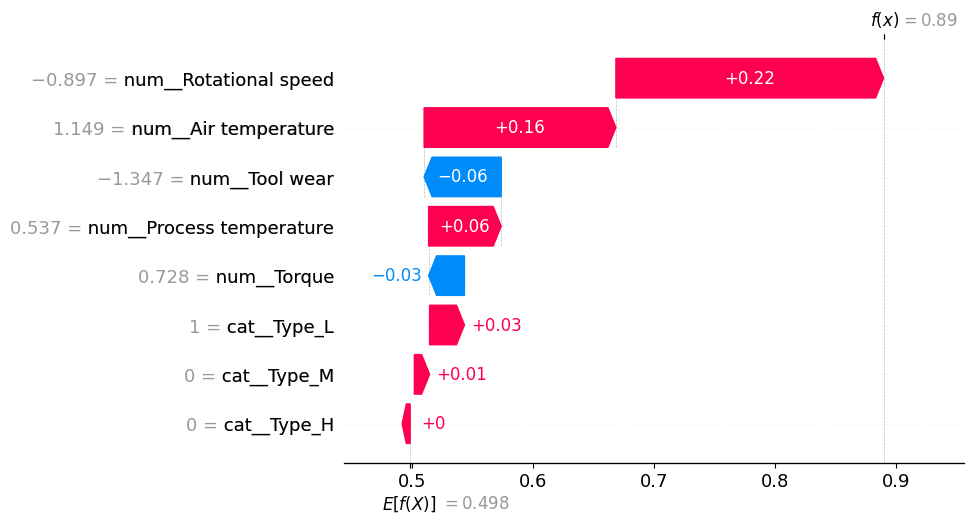

In [10]:
# Select SHAP explanation for this individual machine
if shap_explanation.values.ndim == 3:

    individual_explanation = shap.Explanation(
        values=shap_explanation.values[selected_index, :, 1],
        base_values=shap_explanation.base_values[selected_index, 1],
        data=X_shap.iloc[selected_index].values,
        feature_names=feature_names
    )

else:
    individual_explanation = shap_explanation[selected_index]

# Display waterfall plot
shap.plots.waterfall(individual_explanation)

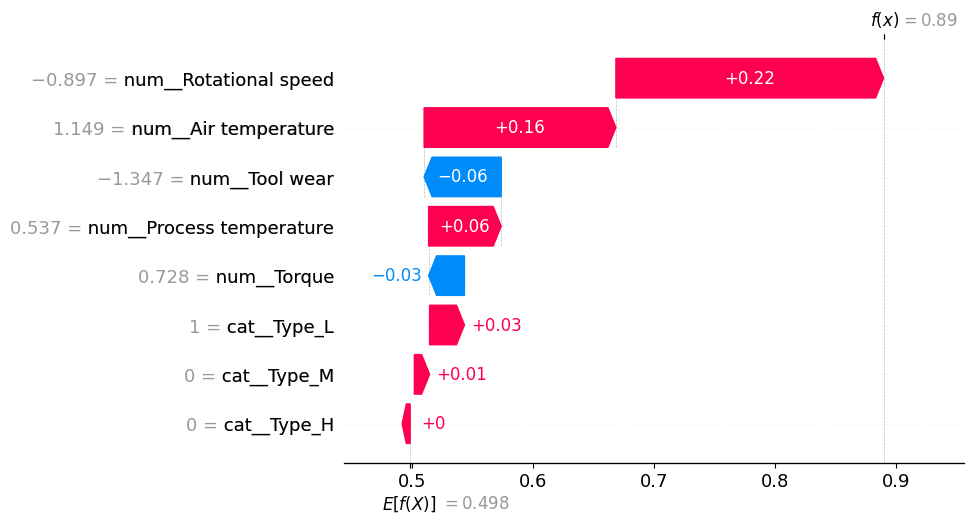

In [11]:
shap.plots.waterfall(individual_explanation)

### Individual SHAP Explanation — Machine 3787

- Predicted failure probability: 0.89 (89%).
- Selected classification threshold: 0.2667.
- Predicted class: Failure (1).
- Baseline model output: 0.498.

**Features increasing the prediction:**
- Rotational speed: +0.22
- Air temperature: +0.16
- Process temperature: +0.06

**Features decreasing the prediction:**
- Tool wear: -0.06
- Torque: -0.03

**Conclusion:** The SHAP waterfall plot explains how individual machine measurements contributed to the model's high failure prediction. Rotational speed and air temperature had the largest positive contributions for this particular record.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Recreate the same train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

categorical_features = ["Type"]

numerical_features = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

# Prepare preprocessing
anomaly_preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Fit preprocessing only on training data
X_train_transformed = anomaly_preprocessor.fit_transform(X_train)

X_test_transformed = anomaly_preprocessor.transform(X_test)

print("Training shape:", X_train_transformed.shape)
print("Testing shape:", X_test_transformed.shape)
print("Preprocessing completed!")

Training shape: (8000, 8)
Testing shape: (2000, 8)
Preprocessing completed!


In [13]:
from sklearn.ensemble import IsolationForest

isolation_model = IsolationForest(
    n_estimators=200,
    contamination=0.03,
    random_state=42,
    n_jobs=-1
)

# Train using features only, without failure labels
isolation_model.fit(X_train_transformed)

print("Isolation Forest trained successfully!")

Isolation Forest trained successfully!


In [14]:
# Predict anomalies
anomaly_predictions = isolation_model.predict(X_test_transformed)

# Calculate anomaly scores
anomaly_scores = isolation_model.decision_function(
    X_test_transformed
)

# Count normal and anomalous records
unique, counts = np.unique(
    anomaly_predictions,
    return_counts=True
)

print("Anomaly detection results:")

for label, count in zip(unique, counts):
    if label == 1:
        print("Normal records:", count)
    else:
        print("Anomalies detected:", count)

print("Total test records:", len(X_test))

Anomaly detection results:
Anomalies detected: 60
Normal records: 1940
Total test records: 2000


In [15]:
from sklearn.metrics import confusion_matrix

# Convert Isolation Forest output:
# -1 = anomaly, 1 = normal
anomaly_flags = (anomaly_predictions == -1).astype(int)

cm_anomaly = confusion_matrix(
    y_test,
    anomaly_flags
)

print("Rows: Actual labels (Normal, Failure)")
print("Columns: Predicted labels (Normal, Anomaly)")
print(cm_anomaly)

print("\nFailure records detected as anomalies:",
      ((y_test.to_numpy() == 1) & (anomaly_flags == 1)).sum())

print("Total actual failures:",
      (y_test.to_numpy() == 1).sum())

Rows: Actual labels (Normal, Failure)
Columns: Predicted labels (Normal, Anomaly)
[[1881   51]
 [  59    9]]

Failure records detected as anomalies: 9
Total actual failures: 68


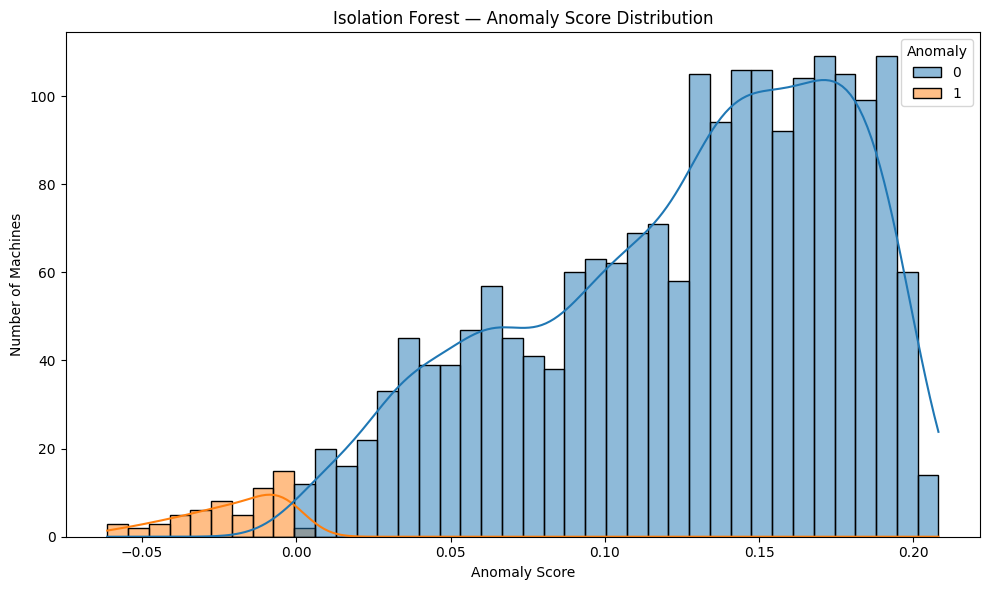

In [16]:
# Create a results dataframe
anomaly_results = X_test.copy()

anomaly_results["Actual Failure"] = y_test.to_numpy()
anomaly_results["Anomaly"] = anomaly_flags
anomaly_results["Anomaly Score"] = anomaly_scores

# Plot anomaly scores
plt.figure(figsize=(10, 6))

sns.histplot(
    data=anomaly_results,
    x="Anomaly Score",
    hue="Anomaly",
    bins=40,
    kde=True
)

plt.title("Isolation Forest — Anomaly Score Distribution")
plt.xlabel("Anomaly Score")
plt.ylabel("Number of Machines")
plt.tight_layout()
plt.show()

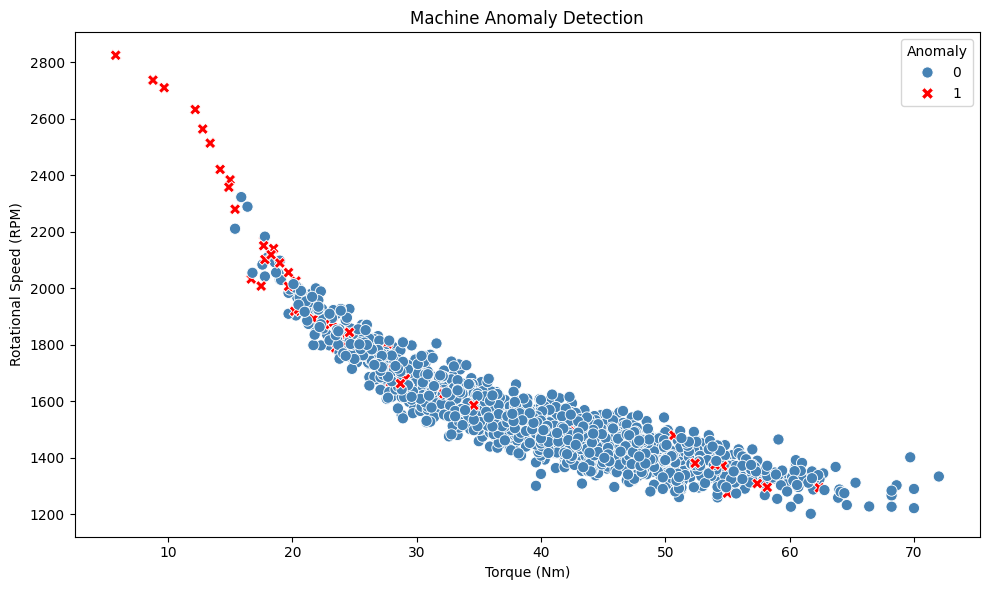

In [17]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=anomaly_results,
    x="Torque",
    y="Rotational speed",
    hue="Anomaly",
    style="Anomaly",
    palette={0: "steelblue", 1: "red"},
    s=65
)

plt.title("Machine Anomaly Detection")
plt.xlabel("Torque (Nm)")
plt.ylabel("Rotational Speed (RPM)")
plt.tight_layout()
plt.show()

### Isolation Forest — Anomaly Detection Findings

- Isolation Forest was trained using 8,000 training records.
- It used six original machine input features.
- The contamination parameter was set to 0.03.
- Testing was performed on 2,000 records.
- 1,940 records were classified as normal.
- 60 records were classified as anomalies.

**Comparison with actual failure labels:**
- Actual failures: 68
- Failures detected as anomalies: 9
- Normal records incorrectly flagged: 51
- Failure detection recall: 13.24%
- Anomaly precision: 15%

**Conclusion:**

Isolation Forest identified unusual operating patterns without using failure labels during training. However, its overlap with actual machine failures was limited. Anomaly detection should therefore complement, not replace, the supervised failure prediction model.


In [18]:
import os
import joblib

os.makedirs("models", exist_ok=True)

# Save Isolation Forest and preprocessing together
anomaly_artifact = {
    "model": isolation_model,
    "preprocessor": anomaly_preprocessor,
    "contamination": 0.03,
    "features": list(X.columns)
}

joblib.dump(
    anomaly_artifact,
    "models/isolation_forest_model.joblib"
)

# Save SHAP global feature importance
shap_importance.to_csv(
    "models/shap_feature_importance.csv",
    index=False
)

print("Artifacts saved successfully!")

print(os.listdir("models"))

Artifacts saved successfully!
['shap_feature_importance.csv', 'isolation_forest_model.joblib']


In [19]:
saved_artifact = joblib.load(
    "models/isolation_forest_model.joblib"
)

loaded_anomaly_model = saved_artifact["model"]
loaded_preprocessor = saved_artifact["preprocessor"]

print("Model loaded successfully!")

test_prediction = loaded_anomaly_model.predict(
    loaded_preprocessor.transform(X_test.iloc[[0]])
)

print("Test prediction:", test_prediction)


Model loaded successfully!
Test prediction: [1]
